In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Proje ortamı hazır!")

Python: 3.11.9
Pandas: 3.1.1
NumPy: 2.4.6
Scikit-learn: 1.9.1
Proje ortamı hazır!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri setini yükle
df = pd.read_csv("energydata_complete.csv")

# Tarih sütununu tarih formatına dönüştür
df["date"] = pd.to_datetime(df["date"])

print("Veri seti başarıyla yüklendi!")

print("\nSatır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

# İlk 5 satırı göster
display(df.head())

Veri seti başarıyla yüklendi!

Satır sayısı: 19735
Sütun sayısı: 29


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [5]:
print("=== VERİ SETİ BİLGİLERİ ===")
df.info()

print("\n=== TARİH ARALIĞI ===")
print("Başlangıç:", df["date"].min())
print("Bitiş:", df["date"].max())

print("\n=== EKSİK VERİLER ===")
print(df.isnull().sum())

print("\n=== TEKRAR EDEN ZAMAN DAMGALARI ===")
print(df["date"].duplicated().sum())

print("\n=== ENERJİ TÜKETİMİ KONTROLÜ ===")
print(df["Appliances"].describe())

print("\nNegatif tüketim sayısı:",
      (df["Appliances"] < 0).sum())

print("\n=== SICAKLIK VE NEM ARALIKLARI ===")
for col in ["T1", "T_out", "RH_1", "RH_out"]:
    print(col, "Min:", df[col].min(),
          "Max:", df[col].max())

=== VERİ SETİ BİLGİLERİ ===
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[us]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64

In [6]:
# Günlük toplulaştırma öncesinde
# tekrar eden zaman damgalarını kontrol et
if df["date"].duplicated().any():
    print("UYARI: Tekrar eden zaman damgaları var!")
    print("Günlük hesaplamadan önce incelenmeli.")
else:
    # Gün bilgisini oluştur
    df["day"] = df["date"].dt.floor("D")

    # Günlük enerji ve ölçüm sayısı
    daily = df.groupby("day").agg(
        measurement_count=("Appliances", "count"),
        daily_energy_wh=("Appliances", "sum")
    )

    # Wh -> kWh dönüşümü
    daily["daily_energy_kwh"] = (
        daily["daily_energy_wh"] / 1000
    )

    # Günlük beklenen ölçüm sayısı: 144
    daily["coverage_ratio"] = (
        daily["measurement_count"] / 144
    )

    # Günlük ölçüm kapsaması
    daily["coverage_percent"] = (
        daily["coverage_ratio"] * 100
    )

    print("Toplam gün:", len(daily))
    print(
        "Tam kapsamalı gün:",
        (daily["measurement_count"] == 144).sum()
    )

    print("\nİlk 10 günlük kayıt:")
    display(daily.head(10))

    print("\nGünlük enerji istatistikleri:")
    display(daily["daily_energy_kwh"].describe())

Toplam gün: 138
Tam kapsamalı gün: 136

İlk 10 günlük kayıt:


,measurement_count,daily_energy_wh,daily_energy_kwh,coverage_ratio,coverage_percent
day,,,,,
2016-01-11,42,5740,5.74,0.291667,29.166667
2016-01-12,144,12340,12.34,1.000000,100.000000
2016-01-13,144,13970,13.97,1.000000,100.000000
2016-01-14,144,21800,21.80,1.000000,100.000000
2016-01-15,144,18050,18.05,1.000000,100.000000
2016-01-16,144,18040,18.04,1.000000,100.000000
2016-01-17,144,20550,20.55,1.000000,100.000000
2016-01-18,144,13530,13.53,1.000000,100.000000
2016-01-19,144,11990,11.99,1.000000,100.000000



Günlük enerji istatistikleri:


count    138.000000
mean      13.971087
std        4.393151
min        5.400000
25%       10.812500
50%       13.255000
75%       16.020000
max       27.150000
Name: daily_energy_kwh, dtype: float64

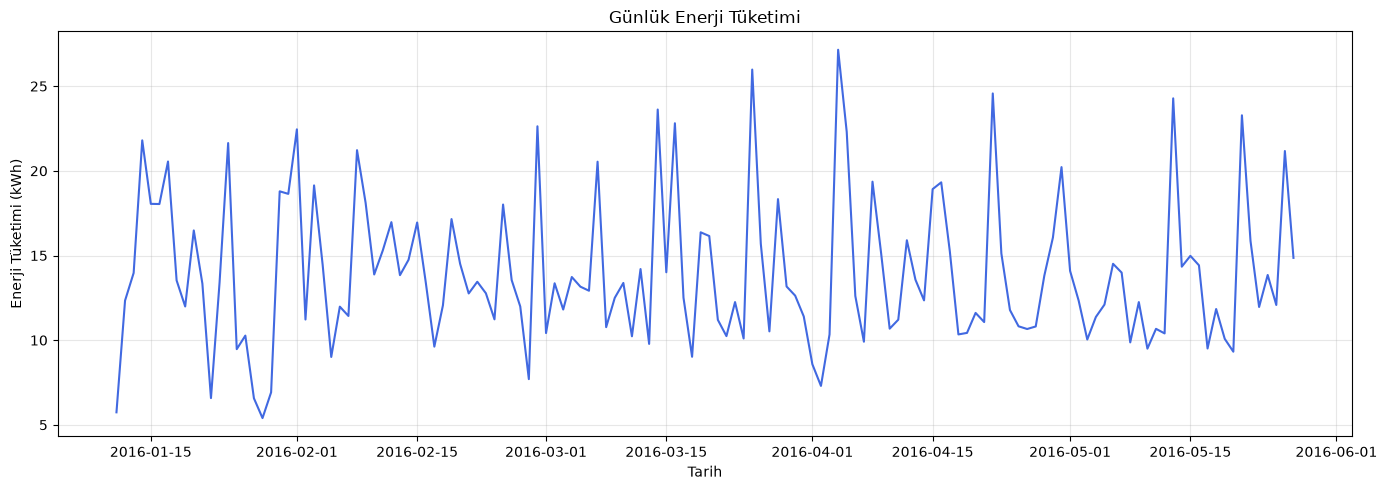

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily.index,
    daily["daily_energy_kwh"],
    color="royalblue",
    linewidth=1.5
)

plt.title("Günlük Enerji Tüketimi")
plt.xlabel("Tarih")
plt.ylabel("Enerji Tüketimi (kWh)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Eksik ölçümlü günleri belirle
eksik_gunler = daily[
    daily["measurement_count"] != 144
]

print("Eksik ölçümlü günler:")
display(eksik_gunler)

# Yalnızca 144 ölçümü bulunan günleri tut
daily_clean = daily[
    daily["measurement_count"] == 144
].copy()

print("Temizlenmiş günlük veri sayısı:", len(daily_clean))

print("Başlangıç:", daily_clean.index.min())
print("Bitiş:", daily_clean.index.max())

print("\nGünlük enerji istatistikleri:")
display(daily_clean["daily_energy_kwh"].describe())

# En az 90 günlük kayıt kontrolü
assert len(daily_clean) >= 90, "90 gün şartı karşılanmıyor!"

print("\nVeri temizleme başarıyla tamamlandı!")

Eksik ölçümlü günler:


,measurement_count,daily_energy_wh,daily_energy_kwh,coverage_ratio,coverage_percent
day,,,,,
2016-01-11,42,5740,5.74,0.291667,29.166667
2016-05-27,109,14860,14.86,0.756944,75.694444


Temizlenmiş günlük veri sayısı: 136
Başlangıç: 2016-01-12 00:00:00
Bitiş: 2016-05-26 00:00:00

Günlük enerji istatistikleri:


count    136.000000
mean      14.025074
std        4.367500
min        5.400000
25%       10.817500
50%       13.255000
75%       16.082500
max       27.150000
Name: daily_energy_kwh, dtype: float64


Veri temizleme başarıyla tamamlandı!


In [12]:
# Günlük çevresel ölçümler
daily_weather = df.groupby("day").agg(
    avg_out_temp=("T_out", "mean"),
    min_out_temp=("T_out", "min"),
    max_out_temp=("T_out", "max"),
    avg_indoor_temp=("T1", "mean"),
    avg_out_humidity=("RH_out", "mean"),
    avg_indoor_humidity=("RH_1", "mean"),
    total_lights_wh=("lights", "sum")
)

# Temizlenmiş enerji tablosuyla birleştir
daily_eda = daily_clean.join(daily_weather)

# Takvim bilgileri
daily_eda["weekday"] = daily_eda.index.day_of_week
daily_eda["month"] = daily_eda.index.month
daily_eda["is_weekend"] = daily_eda["weekday"] >= 5

# Aydınlatma tüketimini kWh cinsine dönüştür
daily_eda["lights_kwh"] = (
    daily_eda["total_lights_wh"] / 1000
)

print("EDA veri tablosu hazır!")
print("Gün sayısı:", len(daily_eda))

display(daily_eda.head())

EDA veri tablosu hazır!
Gün sayısı: 136


,measurement_count,daily_energy_wh,daily_energy_kwh,coverage_ratio,coverage_percent,avg_out_temp,min_out_temp,max_out_temp,avg_indoor_temp,avg_out_humidity,avg_indoor_humidity,total_lights_wh,weekday,month,is_weekend,lights_kwh
day,,,,,,,,,,,,,,,,
2016-01-12,144,12340,12.34,1.0,100.0,5.566319,4.5,7.5,20.092326,87.500000,45.142014,610,1,1,False,0.61
2016-01-13,144,13970,13.97,1.0,100.0,4.856944,2.7,6.9,19.197824,83.406250,42.867772,780,2,1,False,0.78
2016-01-14,144,21800,21.80,1.0,100.0,3.431944,0.9,5.5,20.372078,86.420139,42.435191,720,3,1,False,0.72
2016-01-15,144,18050,18.05,1.0,100.0,2.665278,0.0,4.5,22.280949,88.385417,39.099294,860,4,1,False,0.86
2016-01-16,144,18040,18.04,1.0,100.0,2.194097,0.4,5.9,22.119063,89.649306,39.925671,1150,5,1,True,1.15


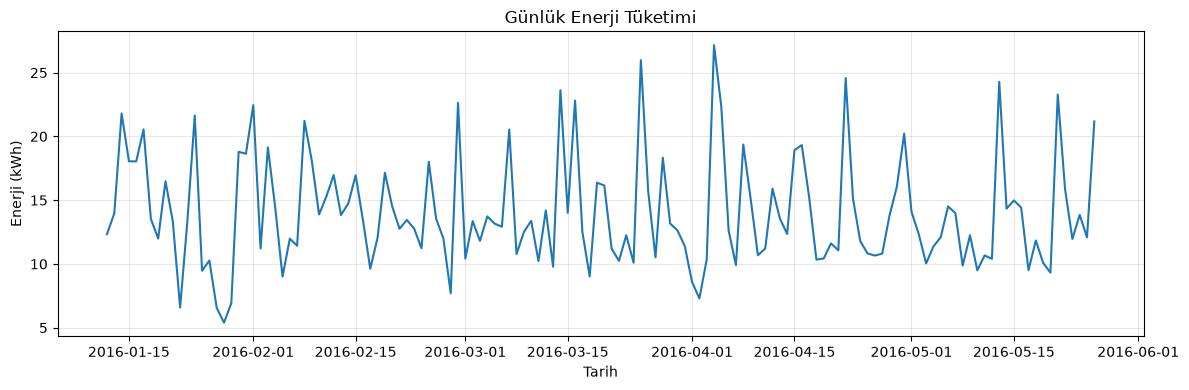

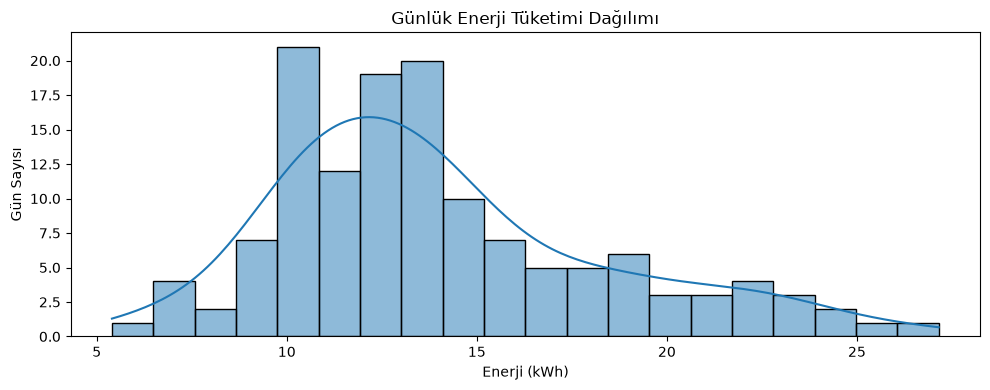

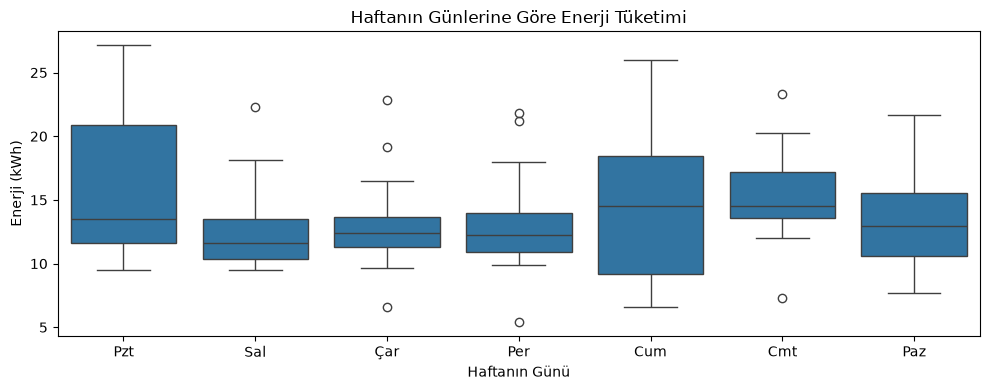

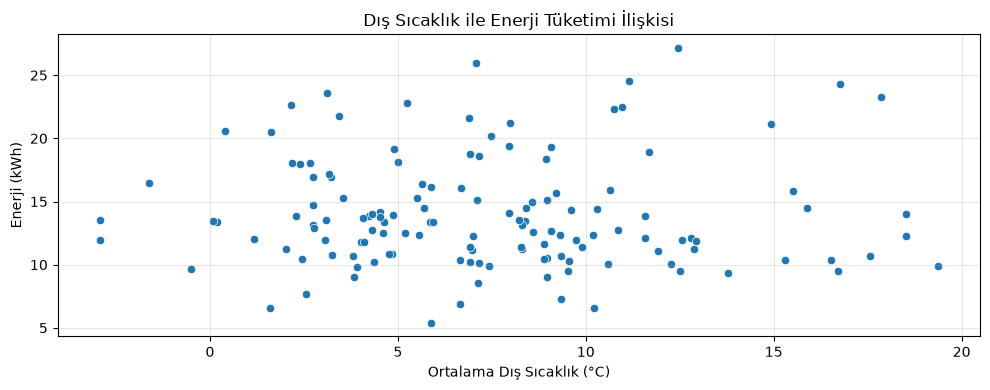

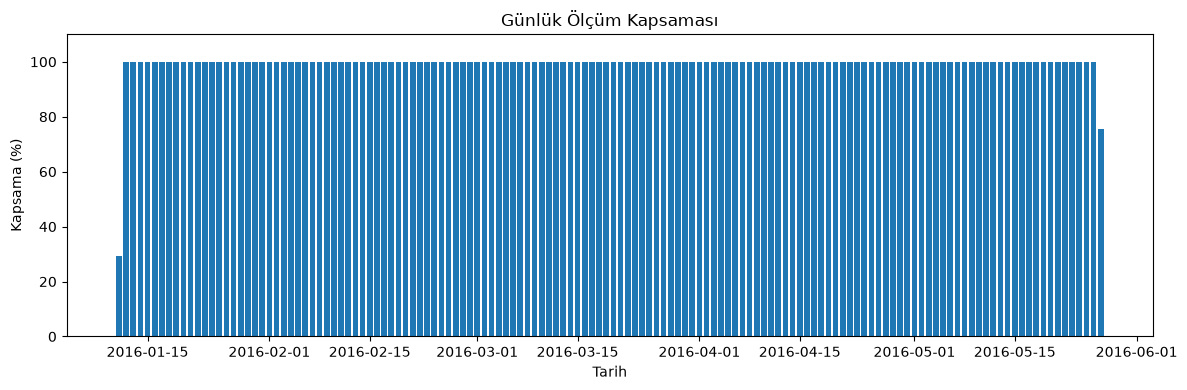

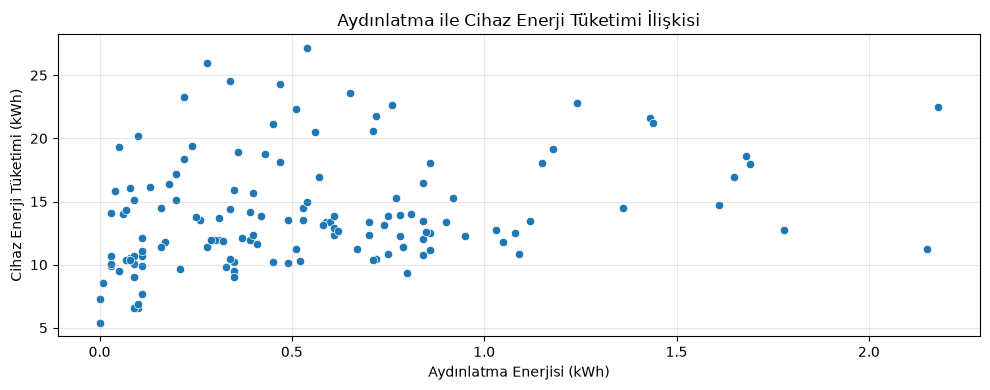

In [10]:
# GRAFİK 1: Günlük enerji tüketimi
plt.figure(figsize=(12, 4))
plt.plot(daily_eda.index, daily_eda["daily_energy_kwh"])
plt.title("Günlük Enerji Tüketimi")
plt.xlabel("Tarih")
plt.ylabel("Enerji (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# GRAFİK 2: Enerji tüketim dağılımı
plt.figure(figsize=(10, 4))
sns.histplot(
    daily_eda["daily_energy_kwh"],
    bins=20,
    kde=True
)
plt.title("Günlük Enerji Tüketimi Dağılımı")
plt.xlabel("Enerji (kWh)")
plt.ylabel("Gün Sayısı")
plt.tight_layout()
plt.show()


# GRAFİK 3: Haftanın günlerine göre tüketim
gunler = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

daily_eda["weekday_name"] = daily_eda["weekday"].map(
    dict(enumerate(gunler))
)

plt.figure(figsize=(10, 4))
sns.boxplot(
    data=daily_eda,
    x="weekday_name",
    y="daily_energy_kwh",
    order=gunler
)
plt.title("Haftanın Günlerine Göre Enerji Tüketimi")
plt.xlabel("Haftanın Günü")
plt.ylabel("Enerji (kWh)")
plt.tight_layout()
plt.show()


# GRAFİK 4: Dış sıcaklık ve enerji tüketimi
plt.figure(figsize=(10, 4))
sns.scatterplot(
    data=daily_eda,
    x="avg_out_temp",
    y="daily_energy_kwh"
)
plt.title("Dış Sıcaklık ile Enerji Tüketimi İlişkisi")
plt.xlabel("Ortalama Dış Sıcaklık (°C)")
plt.ylabel("Enerji (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# GRAFİK 5: Günlük ölçüm kapsaması
plt.figure(figsize=(12, 4))
plt.bar(
    daily.index,
    daily["coverage_percent"],
    width=0.8
)
plt.title("Günlük Ölçüm Kapsaması")
plt.xlabel("Tarih")
plt.ylabel("Kapsama (%)")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()


# GRAFİK 6: Aydınlatma ve enerji tüketimi
plt.figure(figsize=(10, 4))
sns.scatterplot(
    data=daily_eda,
    x="lights_kwh",
    y="daily_energy_kwh"
)
plt.title("Aydınlatma ile Cihaz Enerji Tüketimi İlişkisi")
plt.xlabel("Aydınlatma Enerjisi (kWh)")
plt.ylabel("Cihaz Enerji Tüketimi (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Hafta içi ve hafta sonu karşılaştırması
weekday_avg = daily_eda.loc[
    ~daily_eda["is_weekend"], "daily_energy_kwh"
].mean()

weekend_avg = daily_eda.loc[
    daily_eda["is_weekend"], "daily_energy_kwh"
].mean()

print("Hafta içi ortalama:", round(weekday_avg, 2), "kWh")
print("Hafta sonu ortalama:", round(weekend_avg, 2), "kWh")

# En yüksek tüketimli 5 gün
print("\nEn yüksek tüketimli 5 gün:")
display(
    daily_eda.nlargest(
        5, "daily_energy_kwh"
    )[["daily_energy_kwh", "avg_out_temp", "lights_kwh"]]
)

# En düşük tüketimli 5 gün
print("\nEn düşük tüketimli 5 gün:")
display(
    daily_eda.nsmallest(
        5, "daily_energy_kwh"
    )[["daily_energy_kwh", "avg_out_temp", "lights_kwh"]]
)

Hafta içi ortalama: 13.85 kWh
Hafta sonu ortalama: 14.48 kWh

En yüksek tüketimli 5 gün:


,daily_energy_kwh,avg_out_temp,lights_kwh
day,,,
2016-04-04,27.15,12.443403,0.54
2016-03-25,25.98,7.070833,0.28
2016-04-22,24.57,11.141667,0.34
2016-05-13,24.28,16.774653,0.47
2016-03-14,23.62,3.107292,0.65



En düşük tüketimli 5 gün:


,daily_energy_kwh,avg_out_temp,lights_kwh
day,,,
2016-01-28,5.40,5.869444,0.00
2016-01-27,6.57,10.219097,0.09
2016-01-22,6.58,1.598958,0.10
2016-01-29,6.92,6.651736,0.10
2016-04-02,7.30,9.333681,0.00


In [13]:
# AŞAMA 3.1 - GEÇMİŞ TÜKETİM ÖZELLİKLERİ

features_df = daily_eda.sort_index().copy()

target = features_df["daily_energy_kwh"]

# Bir önceki gün tüketimi
features_df["lag_1"] = target.shift(1)

# Yedi gün önceki tüketim
features_df["lag_7"] = target.shift(7)

# Son üç gün ortalama tüketim
features_df["rolling_3_mean"] = (
    target.shift(1).rolling(3).mean()
)

# Son yedi gün ortalama tüketim
features_df["rolling_7_mean"] = (
    target.shift(1).rolling(7).mean()
)

# Son yedi gün standart sapma
features_df["rolling_7_std"] = (
    target.shift(1).rolling(7).std()
)

# Son yedi gün maksimum tüketim
features_df["rolling_7_max"] = (
    target.shift(1).rolling(7).max()
)

print("Geçmiş tüketim özellikleri oluşturuldu!")

display(features_df[
    [
        "daily_energy_kwh",
        "lag_1",
        "lag_7",
        "rolling_3_mean",
        "rolling_7_mean",
        "rolling_7_std",
        "rolling_7_max"
    ]
].head(12))

Geçmiş tüketim özellikleri oluşturuldu!


,daily_energy_kwh,lag_1,lag_7,rolling_3_mean,rolling_7_mean,rolling_7_std,rolling_7_max
day,,,,,,,
2016-01-12,12.34,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-13,13.97,12.34,NaN,NaN,NaN,NaN,NaN
2016-01-14,21.80,13.97,NaN,NaN,NaN,NaN,NaN
2016-01-15,18.05,21.80,NaN,16.036667,NaN,NaN,NaN
2016-01-16,18.04,18.05,NaN,17.940000,NaN,NaN,NaN
2016-01-17,20.55,18.04,NaN,19.296667,NaN,NaN,NaN
2016-01-18,13.53,20.55,NaN,18.880000,NaN,NaN,NaN
2016-01-19,11.99,13.53,12.34,17.373333,16.897143,3.667196,21.80
2016-01-20,16.48,11.99,13.97,15.356667,16.847143,3.741322,21.80


In [14]:
# AŞAMA 3.2 - HAVA VE AYDINLATMA ÖZELLİKLERİ

# Günlük ilave sensör istatistikleri
extra_weather = df.groupby("day").agg(
    out_humidity_std=("RH_out", "std"),
    indoor_humidity_std=("RH_1", "std"),
    indoor_temp_min=("T1", "min"),
    indoor_temp_max=("T1", "max")
)

features_df = features_df.join(extra_weather)

# Ertesi gün tahmini için yalnızca
# bir önceki günün ölçümlerini kullanıyoruz.

weather_columns = {
    "avg_out_temp": "out_temp_mean_prev1",
    "min_out_temp": "out_temp_min_prev1",
    "max_out_temp": "out_temp_max_prev1",
    "avg_indoor_temp": "indoor_temp_mean_prev1",
    "avg_out_humidity": "out_humidity_mean_prev1",
    "avg_indoor_humidity": "indoor_humidity_mean_prev1",
    "out_humidity_std": "out_humidity_std_prev1",
    "indoor_humidity_std": "indoor_humidity_std_prev1",
    "lights_kwh": "lights_kwh_prev1"
}

for source, new_name in weather_columns.items():
    features_df[new_name] = features_df[source].shift(1)

# Önceki günün sıcaklık aralığı
features_df["out_temp_range_prev1"] = (
    features_df["max_out_temp"]
    - features_df["min_out_temp"]
).shift(1)

# İç ve dış ortam sıcaklığı farkı
features_df["temp_gap_prev1"] = (
    features_df["avg_indoor_temp"]
    - features_df["avg_out_temp"]
).shift(1)

# Takvim özellikleri
features_df["weekday"] = features_df.index.day_of_week
features_df["month"] = features_df.index.month

features_df["is_weekend"] = (
    features_df["weekday"] >= 5
).astype(int)

print("Hava ve takvim özellikleri oluşturuldu!")

display(features_df[
    [
        "out_temp_mean_prev1",
        "out_humidity_mean_prev1",
        "lights_kwh_prev1",
        "temp_gap_prev1",
        "weekday",
        "is_weekend"
    ]
].tail())

Hava ve takvim özellikleri oluşturuldu!


,out_temp_mean_prev1,out_humidity_mean_prev1,lights_kwh_prev1,temp_gap_prev1,weekday,is_weekend
day,,,,,,
2016-05-22,17.851042,74.500000,0.22,5.903110,6,1
2016-05-23,15.513889,90.545139,0.04,9.132521,0,0
2016-05-24,12.570486,84.225694,0.29,11.874560,1,0
2016-05-25,11.568750,76.680556,0.61,12.730590,2,0
2016-05-26,11.563542,74.774306,0.37,12.335811,3,0


In [15]:
# AŞAMA 3.3 - MODEL VERİ TABLOSUNU HAZIRLAMA

feature_cols = [
    # Takvim
    "weekday",
    "month",
    "is_weekend",

    # Geçmiş enerji
    "lag_1",
    "lag_7",
    "rolling_3_mean",
    "rolling_7_mean",
    "rolling_7_std",
    "rolling_7_max",

    # Sıcaklık
    "out_temp_mean_prev1",
    "out_temp_min_prev1",
    "out_temp_max_prev1",
    "out_temp_range_prev1",
    "indoor_temp_mean_prev1",
    "temp_gap_prev1",

    # Nem
    "out_humidity_mean_prev1",
    "indoor_humidity_mean_prev1",
    "out_humidity_std_prev1",
    "indoor_humidity_std_prev1",

    # Aydınlatma
    "lights_kwh_prev1"
]

target_col = "daily_energy_kwh"

# Yeterli geçmiş bilgisi olmayan satırları çıkar
model_df = features_df[
    feature_cols + [target_col]
].dropna().copy()

print("=== MODEL VERİ SETİ ===")

print("Başlangıç:", model_df.index.min())
print("Bitiş:", model_df.index.max())
print("Kullanılabilir gün:", len(model_df))
print("Özellik sayısı:", len(feature_cols))

print("\nEksik değer sayısı:")
print(model_df.isnull().sum().sum())

assert len(model_df) >= 90
assert model_df.index.is_monotonic_increasing
assert model_df.index.is_unique

print("\nModel veri seti hazır!")

display(model_df.head())

=== MODEL VERİ SETİ ===
Başlangıç: 2016-01-19 00:00:00
Bitiş: 2016-05-26 00:00:00
Kullanılabilir gün: 129
Özellik sayısı: 20

Eksik değer sayısı:
0

Model veri seti hazır!


,weekday,month,is_weekend,lag_1,lag_7,rolling_3_mean,rolling_7_mean,rolling_7_std,rolling_7_max,out_temp_mean_prev1,...,out_temp_max_prev1,out_temp_range_prev1,indoor_temp_mean_prev1,temp_gap_prev1,out_humidity_mean_prev1,indoor_humidity_mean_prev1,out_humidity_std_prev1,indoor_humidity_std_prev1,lights_kwh_prev1,daily_energy_kwh
day,,,,,,,,,,,,,,,,,,,,,
2016-01-19,1,1,0,13.53,12.34,17.373333,16.897143,3.667196,21.80,-2.937847,...,-0.400000,4.500000,20.086852,23.024699,82.225694,40.861522,6.373583,0.827337,0.49,11.99
2016-01-20,2,1,0,11.99,13.97,15.356667,16.847143,3.741322,21.80,-2.929167,...,1.700000,6.600000,19.264641,22.193808,83.704861,39.716898,10.488602,0.682364,0.39,16.48
2016-01-21,3,1,0,16.48,21.80,14.000000,17.205714,3.534161,21.80,-1.621875,...,0.600000,5.600000,18.549022,20.170897,88.354167,38.249832,3.678297,1.708737,0.84,13.34
2016-01-22,4,1,0,13.34,18.05,13.936667,15.997143,3.123928,20.55,0.175000,...,4.700000,9.000000,19.039485,18.864485,80.458333,38.149323,12.886202,1.865310,0.59,6.58
2016-01-23,5,1,1,6.58,18.04,12.133333,14.358571,4.550229,20.55,1.598958,...,4.433333,5.733333,18.568102,16.969144,86.041667,38.818912,9.122355,1.210126,0.10,13.40


In [16]:
# AŞAMA 4.1 - KRONOLOJİK VERİ BÖLME

n = len(model_df)

n_train = int(n * 0.70)
n_val = int(n * 0.15)

train_df = model_df.iloc[:n_train].copy()
val_df = model_df.iloc[n_train:n_train + n_val].copy()
test_df = model_df.iloc[n_train + n_val:].copy()

# Özellikler ve hedef
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

# Test dönemi şimdilik saklanıyor.
# Model seçimi için kullanılmayacak.

assert train_df.index.max() < val_df.index.min()
assert val_df.index.max() < test_df.index.min()

print("=== ZAMAN BAZLI VERİ BÖLME ===")

for name, data in [
    ("Eğitim", train_df),
    ("Doğrulama", val_df),
    ("Final test", test_df)
]:
    print(
        f"{name}: {len(data)} gün | "
        f"{data.index.min().date()} - "
        f"{data.index.max().date()}"
    )

print("\nKronolojik veri bölme başarılı!")

=== ZAMAN BAZLI VERİ BÖLME ===
Eğitim: 90 gün | 2016-01-19 - 2016-04-17
Doğrulama: 19 gün | 2016-04-18 - 2016-05-06
Final test: 20 gün | 2016-05-07 - 2016-05-26

Kronolojik veri bölme başarılı!


In [17]:
# AŞAMA 4.2 - MODEL EĞİTİMİ VE KARŞILAŞTIRMA

import time
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Yüksek tüketim eşiği yalnızca eğitimden hesaplanır
high_threshold = y_train.quantile(0.75)

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    errors = actual - predicted
    high_mask = actual >= high_threshold

    return {
        "MAE (kWh)": mean_absolute_error(actual, predicted),
        "RMSE (kWh)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "WAPE (%)": (
            100 * np.abs(errors).sum()
            / np.abs(actual).sum()
        ),
        "Ortalama hata (kWh)": errors.mean(),
        "Yüksek gün MAE": (
            np.abs(errors[high_mask]).mean()
            if high_mask.any() else np.nan
        )
    }

results = []
trained_models = {}
validation_predictions = {}

# MODEL 1: NAIVE BASELINE
baseline_pred = X_val["lag_1"].to_numpy()

baseline_metrics = calculate_metrics(
    y_val, baseline_pred
)

results.append({
    "Model": "Naive Baseline",
    "Parametre": "lag_1",
    "Özellik sayısı": 1,
    "Eğitim süresi (sn)": 0.0,
    **baseline_metrics
})

validation_predictions["Naive Baseline"] = baseline_pred

# MODEL 2: RIDGE - SINIRLI HIPERPARAMETRE ARAMASI
for alpha in [0.1, 1.0, 10.0, 100.0]:

    model_name = f"Ridge alpha={alpha}"

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=alpha))
    ])

    start = time.perf_counter()

    model.fit(X_train, y_train)

    duration = time.perf_counter() - start

    predictions = model.predict(X_val)

    metrics = calculate_metrics(y_val, predictions)

    results.append({
        "Model": model_name,
        "Parametre": f"alpha={alpha}",
        "Özellik sayısı": len(feature_cols),
        "Eğitim süresi (sn)": duration,
        **metrics
    })

    trained_models[model_name] = model
    validation_predictions[model_name] = predictions

# MODEL 3: RANDOM FOREST
rf_name = "Random Forest"

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        max_depth=6,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

start = time.perf_counter()

rf_model.fit(X_train, y_train)

duration = time.perf_counter() - start

rf_predictions = rf_model.predict(X_val)

rf_metrics = calculate_metrics(y_val, rf_predictions)

results.append({
    "Model": rf_name,
    "Parametre": "150 ağaç, depth=6, leaf=2",
    "Özellik sayısı": len(feature_cols),
    "Eğitim süresi (sn)": duration,
    **rf_metrics
})

trained_models[rf_name] = rf_model
validation_predictions[rf_name] = rf_predictions

# SONUÇ TABLOSU
results_df = pd.DataFrame(results)

baseline_mae = baseline_metrics["MAE (kWh)"]

results_df["Baseline iyileşme (%)"] = (
    100 * (
        baseline_mae - results_df["MAE (kWh)"]
    ) / baseline_mae
)

print("=== MODEL KARŞILAŞTIRMA SONUÇLARI ===")
print("Yüksek tüketim eşiği:", round(high_threshold, 2), "kWh")
print("Hata işareti: Pozitif = düşük tahmin")

display(
    results_df.sort_values("MAE (kWh)")
    .round(3)
)

=== MODEL KARŞILAŞTIRMA SONUÇLARI ===
Yüksek tüketim eşiği: 16.45 kWh
Hata işareti: Pozitif = düşük tahmin


,Model,Parametre,Özellik sayısı,Eğitim süresi (sn),MAE (kWh),RMSE (kWh),WAPE (%),Ortalama hata (kWh),Yüksek gün MAE,Baseline iyileşme (%)
0,Naive Baseline,lag_1,1,0.000,3.071,4.559,23.175,-0.039,8.830,0.000
4,Ridge alpha=100.0,alpha=100.0,20,0.007,3.154,3.798,23.805,-1.364,7.393,-2.721
3,Ridge alpha=10.0,alpha=10.0,20,0.007,3.380,4.092,25.508,-1.744,6.939,-10.066
5,Random Forest,"150 ağaç, depth=6, leaf=2",20,0.505,3.524,3.956,26.598,-1.667,6.180,-14.771
1,Ridge alpha=0.1,alpha=0.1,20,0.140,3.578,4.388,27.003,-1.680,7.185,-16.520
2,Ridge alpha=1.0,alpha=1.0,20,0.008,3.615,4.398,27.282,-1.791,7.091,-17.723


In [18]:
# AŞAMA 5.1 - FINAL TEST

from sklearn.base import clone

# Seçilen model: Ridge alpha=100
selected_name = "Ridge alpha=100.0"

# Eğitim ve doğrulama dönemlerini birleştir
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

# Modeli daha fazla geçmiş veriyle yeniden eğit
final_model = clone(trained_models[selected_name])
final_model.fit(X_dev, y_dev)

# Final test
X_test = test_df[feature_cols]
y_test = test_df[target_col]

ridge_test_pred = final_model.predict(X_test)

# Baseline karşılaştırması
baseline_test_pred = X_test["lag_1"].to_numpy()

# Performans hesaplama
ridge_test_metrics = calculate_metrics(
    y_test, ridge_test_pred
)

baseline_test_metrics = calculate_metrics(
    y_test, baseline_test_pred
)

comparison = pd.DataFrame({
    "Naive Baseline": baseline_test_metrics,
    "Ridge alpha=100": ridge_test_metrics
}).T

print("=== FINAL TEST SONUÇLARI ===")
display(comparison.round(3))

print("\nBaseline'a göre MAE iyileşmesi:")
print(round(
    100 * (
        baseline_test_metrics["MAE (kWh)"]
        - ridge_test_metrics["MAE (kWh)"]
    ) / baseline_test_metrics["MAE (kWh)"], 2
), "%")

print("\nBaseline'a göre RMSE iyileşmesi:")
print(round(
    100 * (
        baseline_test_metrics["RMSE (kWh)"]
        - ridge_test_metrics["RMSE (kWh)"]
    ) / baseline_test_metrics["RMSE (kWh)"], 2
), "%")

=== FINAL TEST SONUÇLARI ===


,MAE (kWh),RMSE (kWh),WAPE (%),Ortalama hata (kWh),Yüksek gün MAE
Naive Baseline,4.201,5.966,30.703,0.333,12.310
Ridge alpha=100,3.842,4.589,28.082,-1.317,7.695



Baseline'a göre MAE iyileşmesi:
8.54 %

Baseline'a göre RMSE iyileşmesi:
23.08 %


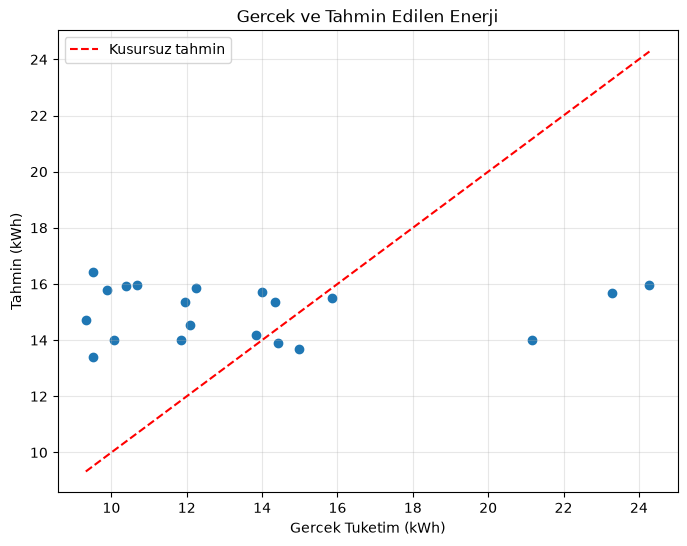

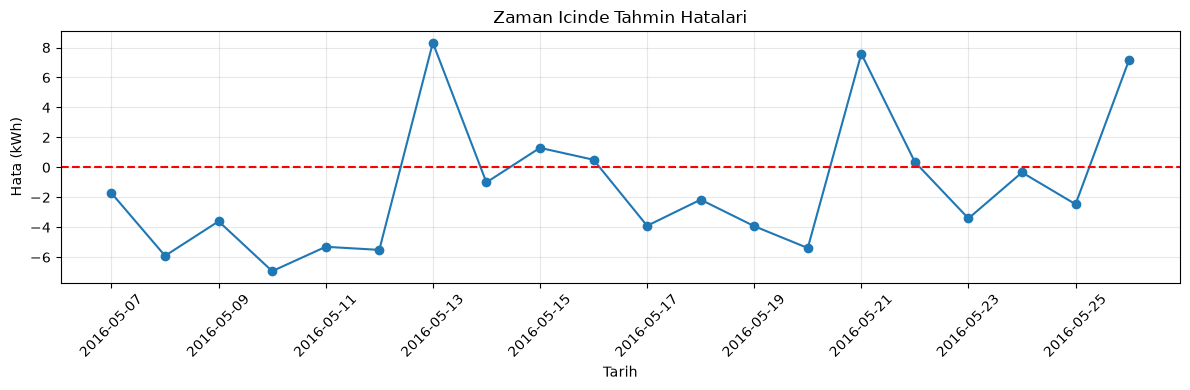

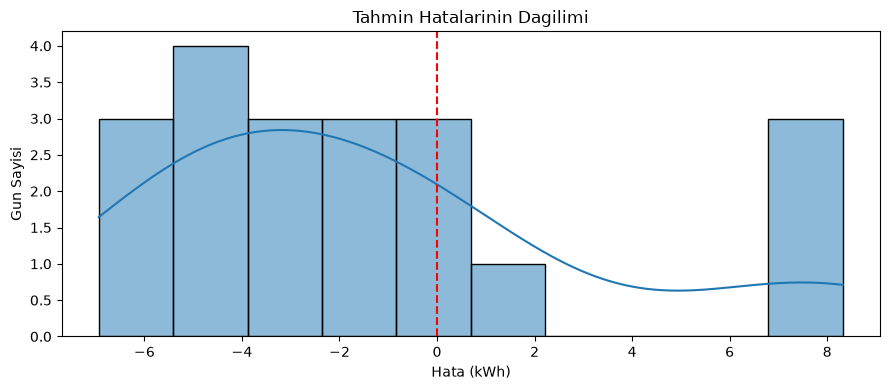

In [19]:
# AŞAMA 5.2 - HATA GRAFİKLERİ

test_results = pd.DataFrame({
    "Gercek_kWh": y_test.to_numpy(),
    "Tahmin_kWh": ridge_test_pred,
    "Baseline_kWh": baseline_test_pred
}, index=y_test.index)

# Pozitif hata: Model düşük tahmin yapmış
test_results["Hata_kWh"] = (
    test_results["Gercek_kWh"]
    - test_results["Tahmin_kWh"]
)

test_results["Mutlak_Hata_kWh"] = (
    test_results["Hata_kWh"].abs()
)

# Grafik 1: Gerçek ve tahmin edilen değerler
plt.figure(figsize=(8, 6))

plt.scatter(
    test_results["Gercek_kWh"],
    test_results["Tahmin_kWh"]
)

min_val = min(
    test_results["Gercek_kWh"].min(),
    test_results["Tahmin_kWh"].min()
)

max_val = max(
    test_results["Gercek_kWh"].max(),
    test_results["Tahmin_kWh"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Kusursuz tahmin"
)

plt.xlabel("Gercek Tuketim (kWh)")
plt.ylabel("Tahmin (kWh)")
plt.title("Gercek ve Tahmin Edilen Enerji")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Grafik 2: Zaman içinde tahmin hataları
plt.figure(figsize=(12, 4))

plt.plot(
    test_results.index,
    test_results["Hata_kWh"],
    marker="o"
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Zaman Icinde Tahmin Hatalari")
plt.xlabel("Tarih")
plt.ylabel("Hata (kWh)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Grafik 3: Hata dağılımı
plt.figure(figsize=(9, 4))

sns.histplot(
    test_results["Hata_kWh"],
    bins=10,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Tahmin Hatalarinin Dagilimi")
plt.xlabel("Hata (kWh)")
plt.ylabel("Gun Sayisi")
plt.tight_layout()
plt.show()

In [20]:
# AŞAMA 5.3 - DETAYLI HATA ANALIZI

print("=== EN BUYUK 5 MUTLAK HATA ===")

display(
    test_results.nlargest(
        5, "Mutlak_Hata_kWh"
    ).round(3)
)

# Eşikler yalnızca eğitim verisinden
low_threshold = y_train.quantile(0.25)

high_days = test_results[
    test_results["Gercek_kWh"] >= high_threshold
]

low_days = test_results[
    test_results["Gercek_kWh"] <= low_threshold
]

print("\nYuksek tuketim esigi:", round(high_threshold, 2))
print("Dusuk tuketim esigi:", round(low_threshold, 2))

for name, subset in [
    ("Yuksek tuketimli gunler", high_days),
    ("Dusuk tuketimli gunler", low_days)
]:
    print("\n", name)
    print("Gun sayisi:", len(subset))

    if len(subset) > 0:
        print(
            "MAE:",
            round(subset["Mutlak_Hata_kWh"].mean(), 3)
        )
        print(
            "Ortalama isaretli hata:",
            round(subset["Hata_kWh"].mean(), 3)
        )

# Dört temel vaka
cases = [
    ("En yuksek tuketim",
     test_results["Gercek_kWh"].idxmax()),
    ("En dusuk tuketim",
     test_results["Gercek_kWh"].idxmin()),
    ("En buyuk pozitif hata",
     test_results["Hata_kWh"].idxmax()),
    ("En buyuk negatif hata",
     test_results["Hata_kWh"].idxmin())
]

case_table = pd.DataFrame([
    {
        "Vaka": label,
        "Tarih": day.date(),
        "Gercek_kWh": test_results.loc[day, "Gercek_kWh"],
        "Tahmin_kWh": test_results.loc[day, "Tahmin_kWh"],
        "Hata_kWh": test_results.loc[day, "Hata_kWh"]
    }
    for label, day in cases
])

print("\n=== VAKA ANALIZI ===")
display(case_table.round(3))

if case_table["Tarih"].nunique() < 4:
    print(
        "UYARI: Vakalarin bazilari ayni gune denk geldi. "
        "Raporda en az 4 farkli gun incelemeliyiz."
    )

=== EN BUYUK 5 MUTLAK HATA ===


,Gercek_kWh,Tahmin_kWh,Baseline_kWh,Hata_kWh,Mutlak_Hata_kWh
day,,,,,
2016-05-13,24.28,15.960,10.40,8.320,8.320
2016-05-21,23.28,15.695,9.32,7.585,7.585
2016-05-26,21.17,13.989,12.08,7.181,7.181
2016-05-10,9.50,16.435,12.25,-6.935,6.935
2016-05-08,9.87,15.780,13.99,-5.910,5.910



Yuksek tuketim esigi: 16.45
Dusuk tuketim esigi: 11.2

 Yuksek tuketimli gunler
Gun sayisi: 3
MAE: 7.695
Ortalama isaretli hata: 7.695

 Dusuk tuketimli gunler
Gun sayisi: 7
MAE: 5.269
Ortalama isaretli hata: -5.269

=== VAKA ANALIZI ===


,Vaka,Tarih,Gercek_kWh,Tahmin_kWh,Hata_kWh
0,En yuksek tuketim,2016-05-13,24.28,15.960,8.320
1,En dusuk tuketim,2016-05-20,9.32,14.708,-5.388
2,En buyuk pozitif hata,2016-05-13,24.28,15.960,8.320
3,En buyuk negatif hata,2016-05-10,9.50,16.435,-6.935


UYARI: Vakalarin bazilari ayni gune denk geldi. Raporda en az 4 farkli gun incelemeliyiz.


=== EN ETKİLİ 15 ÖZELLİK ===


,Ozellik,Katsayi,Mutlak_Etki
6,rolling_7_mean,-0.4423,0.4423
4,lag_7,0.3601,0.3601
3,lag_1,0.3349,0.3349
17,out_humidity_std_prev1,-0.3043,0.3043
5,rolling_3_mean,-0.2413,0.2413
0,weekday,-0.2281,0.2281
8,rolling_7_max,-0.2242,0.2242
11,out_temp_max_prev1,0.1380,0.1380
12,out_temp_range_prev1,0.1030,0.1030
2,is_weekend,0.0902,0.0902


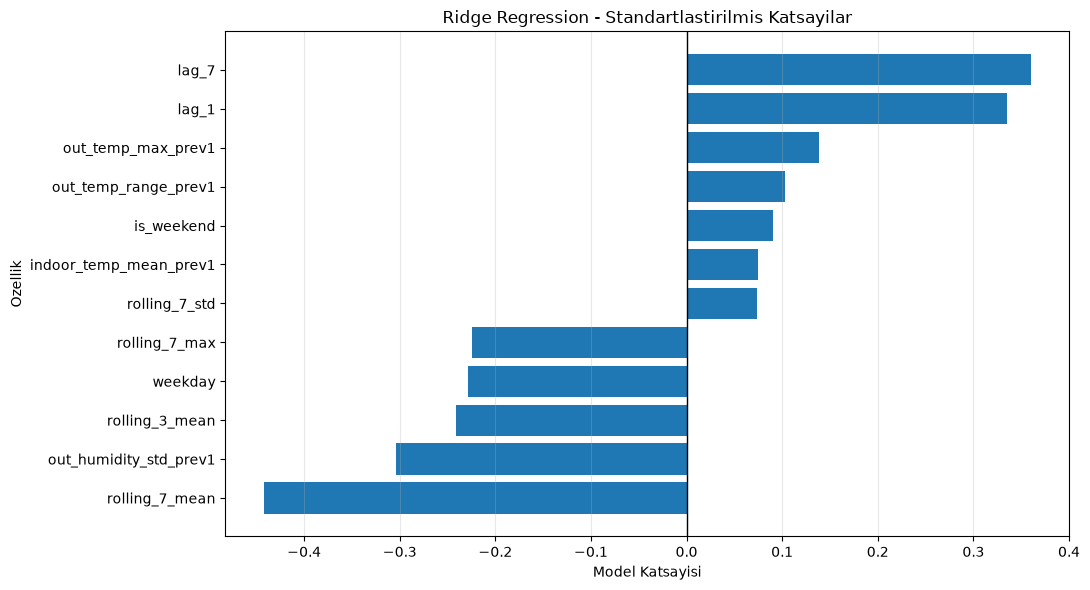

In [21]:
# AŞAMA 6.1 - RIDGE ÖZELLİK ETKİLERİ

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Final Ridge modelinin katsayıları
ridge_regressor = final_model.named_steps["regressor"]

coefficients = ridge_regressor.coef_

importance_df = pd.DataFrame({
    "Ozellik": feature_cols,
    "Katsayi": coefficients,
    "Mutlak_Etki": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    "Mutlak_Etki",
    ascending=False
)

print("=== EN ETKİLİ 15 ÖZELLİK ===")
display(importance_df.head(15).round(4))

# Grafik
top_features = importance_df.head(12).sort_values(
    "Katsayi"
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_features["Ozellik"],
    top_features["Katsayi"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Ridge Regression - Standartlastirilmis Katsayilar")
plt.xlabel("Model Katsayisi")
plt.ylabel("Ozellik")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# AŞAMA 6.2 - DÖRT FARKLI GÜN VAKA ANALİZİ

case_labels = [
    (
        "En yuksek tuketim",
        test_results["Gercek_kWh"].idxmax()
    ),
    (
        "En dusuk tuketim",
        test_results["Gercek_kWh"].idxmin()
    ),
    (
        "En buyuk pozitif hata",
        test_results["Hata_kWh"].idxmax()
    ),
    (
        "En buyuk negatif hata",
        test_results["Hata_kWh"].idxmin()
    )
]

# Tekrar eden tarihleri tek vaka altında birleştir
unique_dates = list(dict.fromkeys(
    day for label, day in case_labels
))

# Dört farklı gün elde edilene kadar
# en büyük diğer hataları ekle
sorted_dates = test_results[
    "Mutlak_Hata_kWh"
].sort_values(ascending=False).index

for day in sorted_dates:
    if len(unique_dates) >= 4:
        break

    if day not in unique_dates:
        unique_dates.append(day)

case_records = []

for day in unique_dates:

    labels = [
        label
        for label, case_day in case_labels
        if case_day == day
    ]

    description = (
        " / ".join(labels)
        if labels
        else "Ek buyuk hata vakasi"
    )

    case_records.append({
        "Tarih": day,
        "Vaka": description,
        "Gercek_kWh": test_results.loc[
            day, "Gercek_kWh"
        ],
        "Tahmin_kWh": test_results.loc[
            day, "Tahmin_kWh"
        ],
        "Hata_kWh": test_results.loc[
            day, "Hata_kWh"
        ],
        "Onceki_gun_kWh": model_df.loc[
            day, "lag_1"
        ],
        "Onceki_gun_sicaklik": model_df.loc[
            day, "out_temp_mean_prev1"
        ],
        "Onceki_gun_aydinlatma": model_df.loc[
            day, "lights_kwh_prev1"
        ]
    })

case_analysis_df = pd.DataFrame(case_records)

print("=== AYRINTILI VAKA ANALİZİ ===")
display(case_analysis_df.round(3))

assert case_analysis_df["Tarih"].nunique() >= 4

print("\nDört farklı günlük vaka analizi tamamlandı!")

=== AYRINTILI VAKA ANALİZİ ===


C:\Users\aysed\AppData\Local\Temp\ipykernel_8360\2652657726.py:82: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(case_analysis_df.round(3))


,Tarih,Vaka,Gercek_kWh,Tahmin_kWh,Hata_kWh,Onceki_gun_kWh,Onceki_gun_sicaklik,Onceki_gun_aydinlatma
0,2016-05-13,En yuksek tuketim / En buyuk pozitif hata,24.28,15.960,8.320,10.40,16.526,0.08
1,2016-05-20,En dusuk tuketim,9.32,14.708,-5.388,10.08,12.265,0.03
2,2016-05-10,En buyuk negatif hata,9.50,16.435,-6.935,12.25,18.520,0.95
3,2016-05-21,Ek buyuk hata vakasi,23.28,15.695,7.585,9.32,13.777,0.80



Dört farklı günlük vaka analizi tamamlandı!


In [23]:
# AŞAMA 6.3 - ANALİZ SONUÇLARINI KAYDETME

from pathlib import Path

output_dir = Path("rapor_ciktilari")
output_dir.mkdir(exist_ok=True)

# Model karşılaştırması
results_df.to_csv(
    output_dir / "model_karsilastirma.csv",
    index=False,
    encoding="utf-8-sig"
)

# Final test sonuçları
test_results.to_csv(
    output_dir / "final_test_sonuclari.csv",
    encoding="utf-8-sig"
)

# Özellik etkileri
importance_df.to_csv(
    output_dir / "ozellik_etkileri.csv",
    index=False,
    encoding="utf-8-sig"
)

# Dört farklı vaka
case_analysis_df.to_csv(
    output_dir / "vaka_analizi.csv",
    index=False,
    encoding="utf-8-sig"
)

# Günlük temiz veri
daily_eda.to_csv(
    output_dir / "gunluk_enerji_verileri.csv",
    encoding="utf-8-sig"
)

print("Analiz dosyalari kaydedildi!")

for file in output_dir.iterdir():
    print(file.name)

Analiz dosyalari kaydedildi!
final_test_sonuclari.csv
gunluk_enerji_verileri.csv
model_karsilastirma.csv
ozellik_etkileri.csv
vaka_analizi.csv


In [24]:
# AŞAMA 7.1 - ÖZELLİK GRUBU KARŞILAŞTIRMASI

from sklearn.base import clone

# Grup A: Takvim + geçmiş tüketim
basic_features = [
    "weekday",
    "month",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_3_mean",
    "rolling_7_mean",
    "rolling_7_std",
    "rolling_7_max"
]

# Grup B: Temel özellikler + hava verileri
weather_features = [
    col for col in feature_cols
    if col != "lights_kwh_prev1"
]

# Grup C: Bütün özellikler
all_features = feature_cols.copy()

feature_groups = {
    "A - Temel": basic_features,
    "B - Temel + Hava": weather_features,
    "C - Temel + Hava + Aydinlatma": all_features
}

ablation_results = []

for group_name, columns in feature_groups.items():

    # Sabit alpha=100 ile Ridge modeli
    model = clone(trained_models["Ridge alpha=100.0"])

    # Yalnızca eğitim verisinde eğit
    model.fit(X_train[columns], y_train)

    # Doğrulama dönemi
    predictions = model.predict(X_val[columns])

    metrics = calculate_metrics(y_val, predictions)

    ablation_results.append({
        "Grup": group_name,
        "Ozellik_Sayisi": len(columns),
        "MAE_kWh": metrics["MAE (kWh)"],
        "RMSE_kWh": metrics["RMSE (kWh)"],
        "WAPE_Yuzde": metrics["WAPE (%)"]
    })

ablation_df = pd.DataFrame(ablation_results)

print("=== OZELLIK GRUBU KARSILASTIRMASI ===")
display(ablation_df.round(3))

print("\n=== EK OZELLIKLERIN KATKISI ===")

basic_mae = ablation_df.loc[0, "MAE_kWh"]
weather_mae = ablation_df.loc[1, "MAE_kWh"]
all_mae = ablation_df.loc[2, "MAE_kWh"]

print(
    "Hava verilerinin MAE katkisi:",
    round(basic_mae - weather_mae, 3),
    "kWh"
)

print(
    "Aydinlatmanin MAE katkisi:",
    round(weather_mae - all_mae, 3),
    "kWh"
)

# Sonuçları kaydet
ablation_df.to_csv(
    output_dir / "ozellik_grubu_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nKarsilastirma dosyasi kaydedildi!")

=== OZELLIK GRUBU KARSILASTIRMASI ===


,Grup,Ozellik_Sayisi,MAE_kWh,RMSE_kWh,WAPE_Yuzde
0,A - Temel,9,3.175,3.849,23.966
1,B - Temel + Hava,19,3.159,3.799,23.840
2,C - Temel + Hava + Aydinlatma,20,3.154,3.798,23.805



=== EK OZELLIKLERIN KATKISI ===
Hava verilerinin MAE katkisi: 0.017 kWh
Aydinlatmanin MAE katkisi: 0.005 kWh

Karsilastirma dosyasi kaydedildi!


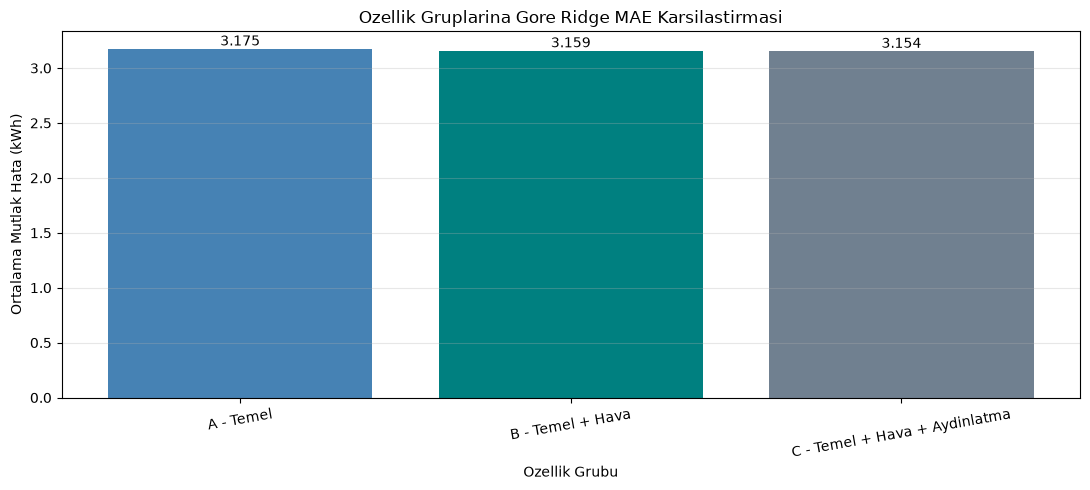

Grafik kaydedildi!


In [25]:
# AŞAMA 7.2 - OZELLIK KARSILASTIRMA GRAFIGI

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

bars = plt.bar(
    ablation_df["Grup"],
    ablation_df["MAE_kWh"],
    color=["steelblue", "teal", "slategray"]
)

plt.title("Ozellik Gruplarina Gore Ridge MAE Karsilastirmasi")
plt.ylabel("Ortalama Mutlak Hata (kWh)")
plt.xlabel("Ozellik Grubu")

plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    output_dir / "ozellik_grubu_karsilastirmasi.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Grafik kaydedildi!")

In [26]:
# AŞAMA 8.1 - MODEL OZELLIKLERI VERI SOZLUGU

feature_info = [
    ("weekday", "date", "Haftanin gunu (0=Pazartesi)", "0-6"),
    ("month", "date", "Tarihten ay bilgisini al", "1-12"),
    ("is_weekend", "date", "Cumartesi/Pazar ise 1, diger gunler 0", "0/1"),

    ("lag_1", "Appliances", "E(t-1)", "kWh"),
    ("lag_7", "Appliances", "E(t-7)", "kWh"),
    ("rolling_3_mean", "Appliances", "Onceki 3 gunun ortalamasi", "kWh"),
    ("rolling_7_mean", "Appliances", "Onceki 7 gunun ortalamasi", "kWh"),
    ("rolling_7_std", "Appliances", "Onceki 7 gunun ornek std sapmasi", "kWh"),
    ("rolling_7_max", "Appliances", "Onceki 7 gunun maksimumu", "kWh"),

    ("out_temp_mean_prev1", "T_out", "Onceki gun sicaklik ortalamasi", "C"),
    ("out_temp_min_prev1", "T_out", "Onceki gun minimum sicaklik", "C"),
    ("out_temp_max_prev1", "T_out", "Onceki gun maksimum sicaklik", "C"),
    ("out_temp_range_prev1", "T_out", "Onceki gun maksimum - minimum", "C"),

    ("indoor_temp_mean_prev1", "T1", "Onceki gun ic sicaklik ortalamasi", "C"),
    ("temp_gap_prev1", "T1, T_out", "Onceki gun ortalama ic - dis sicaklik", "C"),

    ("out_humidity_mean_prev1", "RH_out", "Onceki gun dis nem ortalamasi", "%"),
    ("indoor_humidity_mean_prev1", "RH_1", "Onceki gun ic nem ortalamasi", "%"),
    ("out_humidity_std_prev1", "RH_out", "Onceki gun dis nem std sapmasi", "yuzde puan"),
    ("indoor_humidity_std_prev1", "RH_1", "Onceki gun ic nem std sapmasi", "yuzde puan"),

    ("lights_kwh_prev1", "lights", "Onceki gun toplam Wh / 1000", "kWh")
]

data_dictionary = pd.DataFrame(
    feature_info,
    columns=["Ozellik", "Kaynak_Kolon", "Hesaplama", "Birim"]
)

data_dictionary["Tahmin_Aninda_Mevcut"] = (
    "Evet - gecmis olcum veya takvim bilgisi"
)

# Kullanilan model sutunlari ile eslestir
assert set(data_dictionary["Ozellik"]) == set(feature_cols)
assert len(data_dictionary) == 20

display(data_dictionary)

data_dictionary.to_csv(
    output_dir / "veri_sozlugu.csv",
    index=False,
    encoding="utf-8-sig"
)

print("20 ozellikli veri sozlugu kaydedildi!")

,Ozellik,Kaynak_Kolon,Hesaplama,Birim,Tahmin_Aninda_Mevcut
0,weekday,date,Haftanin gunu (0=Pazartesi),0-6,Evet - gecmis olcum veya takvim bilgisi
1,month,date,Tarihten ay bilgisini al,1-12,Evet - gecmis olcum veya takvim bilgisi
2,is_weekend,date,"Cumartesi/Pazar ise 1, diger gunler 0",0/1,Evet - gecmis olcum veya takvim bilgisi
3,lag_1,Appliances,E(t-1),kWh,Evet - gecmis olcum veya takvim bilgisi
4,lag_7,Appliances,E(t-7),kWh,Evet - gecmis olcum veya takvim bilgisi
5,rolling_3_mean,Appliances,Onceki 3 gunun ortalamasi,kWh,Evet - gecmis olcum veya takvim bilgisi
6,rolling_7_mean,Appliances,Onceki 7 gunun ortalamasi,kWh,Evet - gecmis olcum veya takvim bilgisi
7,rolling_7_std,Appliances,Onceki 7 gunun ornek std sapmasi,kWh,Evet - gecmis olcum veya takvim bilgisi
8,rolling_7_max,Appliances,Onceki 7 gunun maksimumu,kWh,Evet - gecmis olcum veya takvim bilgisi
9,out_temp_mean_prev1,T_out,Onceki gun sicaklik ortalamasi,C,Evet - gecmis olcum veya takvim bilgisi


20 ozellikli veri sozlugu kaydedildi!


In [27]:
# AŞAMA 8.2 - KAYNAK VE ORTAM BILGILERI

import sys
import importlib.metadata as metadata
from pathlib import Path

# Gercek indirme tarihinle degistir
indirme_tarihi = "2026-11-19"

paketler = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "notebook"
]

print("=== PYTHON ORTAMI ===")
print("Python:", sys.version.split()[0])

paket_surümleri = {}

for paket in paketler:
    surum = metadata.version(paket)
    paket_surümleri[paket] = surum
    print(paket, ":", surum)

print("\n=== VERI KAYNAGI ===")
print("Kaynak: UCI Machine Learning Repository")
print("Veri seti: Appliances Energy Prediction")
print("DOI: 10.24432/C5VC8G")
print("Lisans: CC BY 4.0")
print("Dosya: energydata_complete.csv")
print("Indirme tarihi:", indirme_tarihi)

print("\n=== VERI KALITESI ===")
print("Ham satir sayisi:", len(df))
print("Ham sutun sayisi:", len(df.columns) - int("day" in df.columns))
print("Eksik hucre:", df.isna().sum().sum())
print("Tekrarli zaman:", df["date"].duplicated().sum())
print("Negatif cihaz enerjisi:", (df["Appliances"] < 0).sum())
print("Eksik olcumlu gun:", len(eksik_gunler))
print("Gecerli gun:", len(daily_clean))
print("Model gun sayisi:", len(model_df))

# Basit fiziksel sinir kontrolleri
print("\n=== FIZIKSEL SINIR KONTROLLERİ ===")
print("Dis nem 0-100 disinda:",
      (~df["RH_out"].between(0, 100)).sum())

print("Ic nem 0-100 disinda:",
      (~df["RH_1"].between(0, 100)).sum())

print("Dis sicaklik -40 ile 50 C disinda:",
      (~df["T_out"].between(-40, 50)).sum())

# Tarih araliklari
periods = pd.DataFrame([
    {
        "Donem": name,
        "Baslangic": data.index.min().date(),
        "Bitis": data.index.max().date(),
        "Gun": len(data)
    }
    for name, data in [
        ("Egitim", train_df),
        ("Dogrulama", val_df),
        ("Final Test", test_df)
    ]
])

display(periods)

periods.to_csv(
    output_dir / "tarih_araliklari.csv",
    index=False,
    encoding="utf-8-sig"
)

# Metin dosyasina kaydet
info_lines = [
    "AKILLI OFIS ENERJI TAHMINI - TEKNIK BILGILER",
    f"Python: {sys.version.split()[0]}",
    *[f"{k}: {v}" for k, v in paket_surümleri.items()],
    "Kaynak: UCI Appliances Energy Prediction",
    "Atif: Candanedo, L. (2017). Appliances Energy Prediction [Dataset]. UCI Machine Learning Repository.",
    "DOI: 10.24432/C5VC8G",
    "Lisans: CC BY 4.0",
    "Dosya: energydata_complete.csv",
    f"Indirme tarihi: {indirme_tarihi}",
    f"Ham satir: {len(df)}",
    f"Gecerli gun: {len(daily_clean)}",
    f"Model gun sayisi: {len(model_df)}"
]

(output_dir / "teknik_bilgiler.txt").write_text(
    "\n".join(info_lines),
    encoding="utf-8"
)

print("\nTeknik bilgiler kaydedildi!")

=== PYTHON ORTAMI ===
Python: 3.11.9
pandas : 3.1.1
numpy : 2.4.6
matplotlib : 3.11.2
seaborn : 0.13.2
scikit-learn : 1.9.1
notebook : 7.6.5

=== VERI KAYNAGI ===
Kaynak: UCI Machine Learning Repository
Veri seti: Appliances Energy Prediction
DOI: 10.24432/C5VC8G
Lisans: CC BY 4.0
Dosya: energydata_complete.csv
Indirme tarihi: 2026-11-19

=== VERI KALITESI ===
Ham satir sayisi: 19735
Ham sutun sayisi: 29
Eksik hucre: 0
Tekrarli zaman: 0
Negatif cihaz enerjisi: 0
Eksik olcumlu gun: 2
Gecerli gun: 136
Model gun sayisi: 129

=== FIZIKSEL SINIR KONTROLLERİ ===
Dis nem 0-100 disinda: 0
Ic nem 0-100 disinda: 0
Dis sicaklik -40 ile 50 C disinda: 0


,Donem,Baslangic,Bitis,Gun
0,Egitim,2016-01-19,2016-04-17,90
1,Dogrulama,2016-04-18,2016-05-06,19
2,Final Test,2016-05-07,2016-05-26,20



Teknik bilgiler kaydedildi!


In [28]:
# AŞAMA 9.1 - OPERASYONEL RAPOR

from IPython.display import Markdown, display
from pathlib import Path

output_dir = Path("rapor_ciktilari")
output_dir.mkdir(exist_ok=True)

mae = ridge_test_metrics["MAE (kWh)"]
rmse = ridge_test_metrics["RMSE (kWh)"]
wape = ridge_test_metrics["WAPE (%)"]
signed_error = ridge_test_metrics["Ortalama hata (kWh)"]

mae_improvement = 100 * (
    baseline_test_metrics["MAE (kWh)"] - mae
) / baseline_test_metrics["MAE (kWh)"]

rmse_improvement = 100 * (
    baseline_test_metrics["RMSE (kWh)"] - rmse
) / baseline_test_metrics["RMSE (kWh)"]

operasyonel_rapor = f"""
# Tesis Yöneticisi İçin Operasyonel Değerlendirme

## Sistemin Amacı

Geliştirilen sistem, geçmiş cihaz enerji tüketimi,
takvim bilgileri ve geçmiş çevresel ölçümlerden
yararlanarak ertesi günün enerji tüketimini kWh
cinsinden tahmin etmektedir.

Model, otomatik ekipman kontrolü yapmaz ve
tesis yöneticisinin kararının yerine geçmez.

## Tahmin Performansı

7-26 Mayıs 2016 dönemindeki 20 günlük
bağımsız test sonuçları:

- Seçilen model: Ridge Regression (alpha=100)
- MAE: {mae:.3f} kWh
- RMSE: {rmse:.3f} kWh
- WAPE: %{wape:.2f}
- Ortalama işaretli hata: {signed_error:.3f} kWh
- Baseline'a göre MAE iyileşmesi: %{mae_improvement:.2f}
- Baseline'a göre RMSE iyileşmesi: %{rmse_improvement:.2f}

MAE, test dönemindeki günlük mutlak tahmin hatasının
ortalamasıdır. Tek tek günler için garanti edilen
bir hata sınırı değildir.

## Yüksek Tüketim Riski

Eğitim döneminin üst çeyrek eşiği
{high_threshold:.2f} kWh olarak hesaplanmıştır.

Test döneminde yüksek tüketimli 3 günde modelin
ortalama mutlak hatası 7.695 kWh olmuştur.
Bu günlerde model tüketimi düşük tahmin etmiştir.

Tahmini tüketimin yüksek olması veya geçmiş
ölçümlerde olağandışı değişiklik bulunması
halinde tesis yöneticisi ek kontrol yapmalıdır.

## Tahminin Yayınlanmaması Gereken Durumlar

- Gerekli geçmiş günlük ölçümler eksikse
- Günlük 144 ölçüm koşulu sağlanmıyorsa
- Tekrarlı veya güvenilmez zaman kayıtları varsa
- Kritik sensör değerleri fiziksel olarak şüpheliyse
- Modelin uygulanacağı bina, eğitim verisindeki
  koşullardan önemli ölçüde farklıysa
- Veri toplama veya tahmin sürecinde teknik hata varsa

Bu koşullarda otomatik tahmin yayınlanmamalı,
veriler insan tarafından incelenmelidir.

## Modelin İzlenmesi

Tahminler yeni gerçek ölçümlerle karşılaştırılmalı;
MAE, RMSE ve yüksek tüketimli gün hataları
düzenli olarak izlenmelidir.

Başlangıçta aylık performans incelemesi önerilir.
Veri dağılımı veya hata düzeyi belirgin değişirse
model yeniden değerlendirilmelidir.

## Operasyonel Sınırlılıklar

Kaynak veri bir konut binasından toplanmıştır.
Bu nedenle modelin ofis ortamındaki başarısı
ayrıca gerçek ofis verileriyle doğrulanmalıdır.

Modelin mevcut hata düzeyi, kritik enerji
planlamasında tek başına kullanılmasına uygun
olduğunu göstermemektedir.
"""

display(Markdown(operasyonel_rapor))

(output_dir / "operasyonel_rapor.md").write_text(
    operasyonel_rapor,
    encoding="utf-8"
)

print("Operasyonel rapor kaydedildi!")


# Tesis Yöneticisi İçin Operasyonel Değerlendirme

## Sistemin Amacı

Geliştirilen sistem, geçmiş cihaz enerji tüketimi,
takvim bilgileri ve geçmiş çevresel ölçümlerden
yararlanarak ertesi günün enerji tüketimini kWh
cinsinden tahmin etmektedir.

Model, otomatik ekipman kontrolü yapmaz ve
tesis yöneticisinin kararının yerine geçmez.

## Tahmin Performansı

7-26 Mayıs 2016 dönemindeki 20 günlük
bağımsız test sonuçları:

- Seçilen model: Ridge Regression (alpha=100)
- MAE: 3.842 kWh
- RMSE: 4.589 kWh
- WAPE: %28.08
- Ortalama işaretli hata: -1.317 kWh
- Baseline'a göre MAE iyileşmesi: %8.54
- Baseline'a göre RMSE iyileşmesi: %23.08

MAE, test dönemindeki günlük mutlak tahmin hatasının
ortalamasıdır. Tek tek günler için garanti edilen
bir hata sınırı değildir.

## Yüksek Tüketim Riski

Eğitim döneminin üst çeyrek eşiği
16.45 kWh olarak hesaplanmıştır.

Test döneminde yüksek tüketimli 3 günde modelin
ortalama mutlak hatası 7.695 kWh olmuştur.
Bu günlerde model tüketimi düşük tahmin etmiştir.

Tahmini tüketimin yüksek olması veya geçmiş
ölçümlerde olağandışı değişiklik bulunması
halinde tesis yöneticisi ek kontrol yapmalıdır.

## Tahminin Yayınlanmaması Gereken Durumlar

- Gerekli geçmiş günlük ölçümler eksikse
- Günlük 144 ölçüm koşulu sağlanmıyorsa
- Tekrarlı veya güvenilmez zaman kayıtları varsa
- Kritik sensör değerleri fiziksel olarak şüpheliyse
- Modelin uygulanacağı bina, eğitim verisindeki
  koşullardan önemli ölçüde farklıysa
- Veri toplama veya tahmin sürecinde teknik hata varsa

Bu koşullarda otomatik tahmin yayınlanmamalı,
veriler insan tarafından incelenmelidir.

## Modelin İzlenmesi

Tahminler yeni gerçek ölçümlerle karşılaştırılmalı;
MAE, RMSE ve yüksek tüketimli gün hataları
düzenli olarak izlenmelidir.

Başlangıçta aylık performans incelemesi önerilir.
Veri dağılımı veya hata düzeyi belirgin değişirse
model yeniden değerlendirilmelidir.

## Operasyonel Sınırlılıklar

Kaynak veri bir konut binasından toplanmıştır.
Bu nedenle modelin ofis ortamındaki başarısı
ayrıca gerçek ofis verileriyle doğrulanmalıdır.

Modelin mevcut hata düzeyi, kritik enerji
planlamasında tek başına kullanılmasına uygun
olduğunu göstermemektedir.


Operasyonel rapor kaydedildi!


In [29]:
# AŞAMA 9.2 - AI AGENT GECIS PLANI

agent_plani = """
# Enerji Tahmin Sisteminden AI Agent Sistemine Geçiş

## 1. Agent Görevleri

Agent; yeni sensör verilerini düzenli toplama,
ölçüm kalitesini denetleme, günlük tüketimi
hesaplama, tahmin modelini çalıştırma ve
olağandışı tüketim değişikliklerini inceleme
görevlerini üstlenecektir.

Tahmin sonuçlarına ve geçmiş ölçümlere dayanarak
tesis yöneticisine gerekçeli uyarılar sunacaktır.

## 2. İnsan Onayı Gerektiren Kararlar

Enerji bütçesinin değiştirilmesi, cihazların
açılıp kapatılması, klima ve aydınlatma
ayarlarının değiştirilmesi gibi kritik işlemler
insan onayında kalacaktır.

Agent bu işlemleri kendiliğinden yapmayacaktır.

## 3. Veri Kaynakları ve Araçlar

Enerji sayaçları, sıcaklık ve nem sensörleri,
aydınlatma ölçümleri, takvim verileri ve
varsa güvenilir hava tahminleri kullanılacaktır.

Python, pandas, scikit-learn ve zamanlanmış
veri işleme görevleri temel yazılım araçlarıdır.

## 4. Tahmin Modelinin Rolü

Ridge Regression modeli, agent içindeki
tahmin bileşeni olarak görev yapacaktır.

Modelin çıktısı kesin karar değil, yardımcı
bir tüketim tahminidir. Anomali tespiti
ayrı kurallarla veya ayrıca doğrulanmış
bir anomali modeliyle gerçekleştirilecektir.

## 5. Veri Kalitesi ve Performans İzleme

Agent eksik ölçümleri, tekrarlı kayıtları,
beklenmeyen sensör değerlerini ve güncel
olmayan verileri izleyecektir.

Gerçek tüketim verileri geldikçe MAE,
RMSE ve yüksek tüketimli gün hataları
hesaplanacaktır. Veri dağılımındaki
değişimler ayrıca takip edilecektir.

## 6. Güvenlik Önlemleri

Yanlış önerileri azaltmak için veri
doğrulama, açıklanabilir sonuçlar,
yetkilendirme, işlem kayıtları ve insan
onayı mekanizmaları kullanılacaktır.

## 7. Öneri Üretilmemesi Gereken Durumlar

Eksik veya güvenilmez ölçümler, güncel
olmayan veri, kritik sensör arızası,
modelin geçerli kullanım alanı dışındaki
koşullar ya da ciddi performans bozulması
durumunda agent öneri üretmeyi durduracak
ve insan incelemesi isteyecektir.

## 8. Üretim Sistemine Geçiş

İlk aşamada mevcut Notebook modeli
tekrarlanabilir bir tahmin servisine
dönüştürülecektir.

İkinci aşamada veri toplama, kalite kontrolü,
izleme ve anomali uyarıları eklenecektir.

Üçüncü aşamada gerçek ofis verileriyle
pilot uygulama gerçekleştirilecektir.

Son aşamada güvenlik ve performans
testlerinden sonra kontrollü üretim
ortamına geçilecektir. Kritik kararların
insan onayında kalması korunacaktır.
"""

display(Markdown(agent_plani))

(output_dir / "agent_gecis_plani.md").write_text(
    agent_plani,
    encoding="utf-8"
)

print("AI Agent gecis plani kaydedildi!")


# Enerji Tahmin Sisteminden AI Agent Sistemine Geçiş

## 1. Agent Görevleri

Agent; yeni sensör verilerini düzenli toplama,
ölçüm kalitesini denetleme, günlük tüketimi
hesaplama, tahmin modelini çalıştırma ve
olağandışı tüketim değişikliklerini inceleme
görevlerini üstlenecektir.

Tahmin sonuçlarına ve geçmiş ölçümlere dayanarak
tesis yöneticisine gerekçeli uyarılar sunacaktır.

## 2. İnsan Onayı Gerektiren Kararlar

Enerji bütçesinin değiştirilmesi, cihazların
açılıp kapatılması, klima ve aydınlatma
ayarlarının değiştirilmesi gibi kritik işlemler
insan onayında kalacaktır.

Agent bu işlemleri kendiliğinden yapmayacaktır.

## 3. Veri Kaynakları ve Araçlar

Enerji sayaçları, sıcaklık ve nem sensörleri,
aydınlatma ölçümleri, takvim verileri ve
varsa güvenilir hava tahminleri kullanılacaktır.

Python, pandas, scikit-learn ve zamanlanmış
veri işleme görevleri temel yazılım araçlarıdır.

## 4. Tahmin Modelinin Rolü

Ridge Regression modeli, agent içindeki
tahmin bileşeni olarak görev yapacaktır.

Modelin çıktısı kesin karar değil, yardımcı
bir tüketim tahminidir. Anomali tespiti
ayrı kurallarla veya ayrıca doğrulanmış
bir anomali modeliyle gerçekleştirilecektir.

## 5. Veri Kalitesi ve Performans İzleme

Agent eksik ölçümleri, tekrarlı kayıtları,
beklenmeyen sensör değerlerini ve güncel
olmayan verileri izleyecektir.

Gerçek tüketim verileri geldikçe MAE,
RMSE ve yüksek tüketimli gün hataları
hesaplanacaktır. Veri dağılımındaki
değişimler ayrıca takip edilecektir.

## 6. Güvenlik Önlemleri

Yanlış önerileri azaltmak için veri
doğrulama, açıklanabilir sonuçlar,
yetkilendirme, işlem kayıtları ve insan
onayı mekanizmaları kullanılacaktır.

## 7. Öneri Üretilmemesi Gereken Durumlar

Eksik veya güvenilmez ölçümler, güncel
olmayan veri, kritik sensör arızası,
modelin geçerli kullanım alanı dışındaki
koşullar ya da ciddi performans bozulması
durumunda agent öneri üretmeyi durduracak
ve insan incelemesi isteyecektir.

## 8. Üretim Sistemine Geçiş

İlk aşamada mevcut Notebook modeli
tekrarlanabilir bir tahmin servisine
dönüştürülecektir.

İkinci aşamada veri toplama, kalite kontrolü,
izleme ve anomali uyarıları eklenecektir.

Üçüncü aşamada gerçek ofis verileriyle
pilot uygulama gerçekleştirilecektir.

Son aşamada güvenlik ve performans
testlerinden sonra kontrollü üretim
ortamına geçilecektir. Kritik kararların
insan onayında kalması korunacaktır.


AI Agent gecis plani kaydedildi!


In [30]:
# AŞAMA 9.3 - PROJE ARSIVI

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

zip_path = Path("Akilli_Ofis_Proje_Dosyalari.zip")

notebook_path = Path("Enerji_Tahmin_Analizi.ipynb")
dataset_path = Path("energydata_complete.csv")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as zip_file:

    for file in [notebook_path, dataset_path]:
        if file.exists():
            zip_file.write(file, arcname=file.name)
        else:
            print("Dosya bulunamadi:", file)

    for file in output_dir.rglob("*"):
        if file.is_file():
            zip_file.write(file, arcname=str(file))

print("Proje arsivi hazir:", zip_path.resolve())
print("Boyut (MB):", round(zip_path.stat().st_size / 1024**2, 2))

Proje arsivi hazir: C:\Users\aysed\Documents\Akilli_Ofis_Enerji_Tahmini\Akilli_Ofis_Proje_Dosyalari.zip
Boyut (MB): 2.17
